# South India Power Outage: Before vs After Cleaning

This notebook compares the **raw** national dataset (`daily-power-outage.csv`) with the **cleaned** Power BI dataset (`cleaned_south_outage_powerbi.csv`) and then analyses the cleaned data.

**Structure**
1. Load data
2. Before vs after: size, schema, missing values
3. Reconstructing the cleaning steps (and proving they reproduce the cleaned file)
4. Analysis of the cleaned data: trends, states, fuel types, causes, stations, seasonality
5. Key findings

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200, 'display.max_columns', 50, 'display.float_format', '{:,.2f}'.format)

# Paths relative to the notebooks/ folder (see data/README.md for where to get the files)
RAW_PATH   = '../data/raw/daily-power-outage.csv'
CLEAN_PATH = '../data/processed/cleaned_south_outage_powerbi.csv'

raw   = pd.read_csv(RAW_PATH, low_memory=False, parse_dates=['date'])
clean = pd.read_csv(CLEAN_PATH, low_memory=False, parse_dates=['date'])
print('raw  :', raw.shape)
print('clean:', clean.shape)

raw  : (4265703, 15)
clean: (580825, 20)


## 1. Before vs after: the headline numbers

In [2]:
summary = pd.DataFrame({
    'Raw (before)': {
        'Rows': len(raw), 'Columns': raw.shape[1],
        'Regions': raw.region.nunique(), 'States/UTs': raw.state_name.nunique(),
        'Power stations': raw.power_station.nunique(),
        'Date min': raw.date.min().date(), 'Date max': raw.date.max().date(),
        'Exact duplicate rows (ignoring id)': int(raw.drop(columns='id').duplicated().sum()),
    },
    'Cleaned (after)': {
        'Rows': len(clean), 'Columns': clean.shape[1],
        'Regions': 1, 'States/UTs': clean.state_name.nunique(),
        'Power stations': clean.power_station.nunique(),
        'Date min': clean.date.min().date(), 'Date max': clean.date.max().date(),
        'Exact duplicate rows (ignoring id)': int(clean.duplicated().sum()),
    }
})
summary

,Raw (before),Cleaned (after)
Rows,4265703,580825
Columns,15,20
Regions,6,1
States/UTs,35,7
Power stations,604,163
Date min,2017-09-01,2018-01-01
Date max,2025-04-22,2024-12-10
Exact duplicate rows (ignoring id),1680000,0


                           Step  Rows after step  Rows removed
                       Raw file          4265703             0
      Keep Southern region only          1031557       3234146
    Trim to cleaned date window           957828         73729
Drop duplicate unit-day records           580825        377003

Matches cleaned row count exactly: True


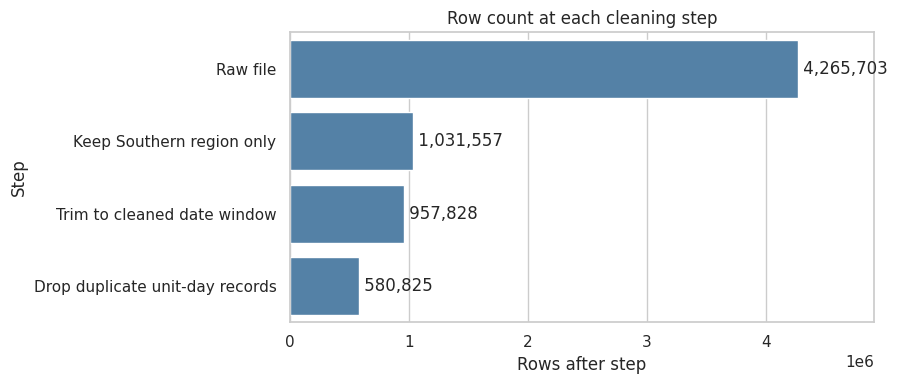

In [3]:
# Where did the rows go? Waterfall from raw to cleaned
key = ['date','state_name','power_station','power_station_unit']
step0 = len(raw)
s1 = raw[raw.region == 'Southern']
s2 = s1[(s1.date >= clean.date.min()) & (s1.date <= clean.date.max())]
s3 = s2.drop_duplicates(key)

waterfall = pd.DataFrame({
    'Step': ['Raw file', 'Keep Southern region only', 'Trim to cleaned date window', 'Drop duplicate unit-day records'],
    'Rows after step': [step0, len(s1), len(s2), len(s3)],
})
waterfall['Rows removed'] = -waterfall['Rows after step'].diff().fillna(0).astype(int)
print(waterfall.to_string(index=False))
print('\nMatches cleaned row count exactly:', len(s3) == len(clean))

fig, ax = plt.subplots(figsize=(9,4))
sns.barplot(data=waterfall, y='Step', x='Rows after step', color='steelblue', ax=ax)
for i, v in enumerate(waterfall['Rows after step']): ax.text(v, i, f' {v:,}', va='center')
ax.set_title('Row count at each cleaning step'); ax.set_xlim(0, step0*1.15); plt.tight_layout(); plt.show()

**Reading this:** most of the shrinkage comes from filtering to the Southern region and from duplicates. The raw file contains the same unit-day records more than once (the `id` differs, everything else is identical), so counting them would inflate outage totals.

## 2. Schema changes

In [4]:
raw_cols, clean_cols = set(raw.columns), set(clean.columns)
print('Dropped:', sorted(raw_cols - clean_cols))
print('Added  :', sorted(clean_cols - raw_cols))
print('Renamed (by logic): station_type -> fuel_type, cap_under_outage -> loss_mw')

Dropped: ['cap_under_outage', 'id', 'region', 'state_code', 'station_type']
Added  : ['Major_Category1', 'Year', 'cause_category', 'cause_recorded', 'fuel_type', 'in_service', 'loss_mw', 'not_operational', 'outage_age_days', 'shortfall_not_outage']
Renamed (by logic): station_type -> fuel_type, cap_under_outage -> loss_mw


In [5]:
miss = pd.DataFrame({
    'raw % missing (Southern, same window)': s2.isna().mean() * 100,
    'cleaned % missing': clean.isna().mean() * 100,
}).round(2)
miss

,"raw % missing (Southern, same window)",cleaned % missing
Major_Category1,NaN,0.00
Year,NaN,0.00
cap_under_outage,4.79,NaN
cause_category,NaN,0.00
cause_recorded,NaN,0.00
date,0.00,0.00
expected_sync_date,97.01,97.03
fuel_type,NaN,0.00
id,0.00,NaN
in_service,NaN,0.00


Most columns that were heavily null in the raw data (`outage_type`, `remarks`, `cap_under_outage`) are fully populated in the cleaned data. The remaining nulls (`outage_date`, `expected_sync_date`, `outage_age_days`) are *legitimately* empty when a unit has no active outage.

## 3. Reconstructing each cleaning step
Below, the raw rows (Southern, deduplicated) are joined to the cleaned rows on the unit-day key so each transformation can be verified.

In [6]:
m = s3.merge(clean, on=key, suffixes=('_raw','_clean'))
print('Joined rows:', len(m), '| cleaned rows:', len(clean))

Joined rows: 580825 | cleaned rows: 580825


### 3.1 `station_type` → `fuel_type`

In [7]:
pd.crosstab(m.station_type, m.fuel_type, margins=True)

fuel_type,Coal/Lignite,Diesel,Gas,Hydro,Nuclear,All
station_type,,,,,,
Hydro,0,0,0,172063,0,172063
Nuclear,0,0,0,0,19946,19946
Ther (Dg),0,16733,0,0,0,16733
Ther (Gt),0,0,58926,0,0,58926
Thermal,313157,0,0,0,0,313157
All,313157,16733,58926,172063,19946,580825


### 3.2 `outage_type`: blanks become `No Outage`

In [8]:
pd.crosstab(m.outage_type_raw.fillna('(blank)'), m.outage_type_clean)

outage_type_clean,Long Duration Outage,No Outage,Planned Outage,Short Duration Outage,Unit Synchronised
outage_type_raw,,,,,
(blank),0,484963,0,0,0
Long Duration Outage,45002,0,0,0,0
Planned Outage,0,0,14670,0,0
Short Duration Outage,0,0,0,27859,0
Unit Synchronised,0,0,0,0,8331


### 3.3 `cap_under_outage` → `loss_mw`

In [9]:
same = (m.cap_under_outage.fillna(0) == m.loss_mw)
print(f'loss_mw equals cap_under_outage (nulls as 0): {same.mean():.3%}')
diff = m[~same]
print(f'{len(diff)} rows differ. In every one, cap_under_outage was null and loss_mw was set to the full monitored capacity:')
print('  all null in raw:', diff.cap_under_outage.isna().all(), '| loss == capacity:', (diff.loss_mw == diff.monitored_capacity_clean).all())
print(diff.outage_type_clean.value_counts())

loss_mw equals cap_under_outage (nulls as 0): 99.985%
89 rows differ. In every one, cap_under_outage was null and loss_mw was set to the full monitored capacity:
  all null in raw: True | loss == capacity: True
outage_type_clean
Short Duration Outage    87
Planned Outage            2
Name: count, dtype: int64


### 3.4 `remarks`: blanks become `No remark`

In [10]:
print('Match after filling blanks:', (m.remarks_raw.fillna('No remark') == m.remarks_clean).mean())
print('Distinct remark texts raw -> clean:', raw.remarks.nunique(), '->', clean.remarks.nunique())

Match after filling blanks: 1.0
Distinct remark texts raw -> clean: 526 -> 355


### 3.5 New derived columns

In [11]:
derived = ['Year','not_operational','in_service','shortfall_not_outage','cause_recorded','outage_age_days','Major_Category1','cause_category']
print(clean[derived].describe(include='all').T[['count','unique','top','freq','mean']].fillna(''))

print('\nnot_operational  = new/unstabilised units:')
print(m[m.not_operational].remarks_raw.value_counts())
print('\nshortfall_not_outage = a loss was reported while outage_type is "No Outage" (backing down / low schedule):')
print(clean.groupby('shortfall_not_outage').outage_type.value_counts().unstack(0).fillna(0).astype(int))

                          count unique      top    freq     mean
Year                 580,825.00                         2,021.02
not_operational          580825      2    False  558872         
in_service               580825      2     True  546651         
shortfall_not_outage     580825      2    False  474229         
cause_recorded           580825      2     True  479595         
outage_age_days      100,177.00                           256.07
Major_Category1          580825     12  Unknown  457686         
cause_category           580825      8  No loss  385056         

not_operational  = new/unstabilised units:
remarks_raw
Unit Not Yet Commissioned    21801
Non Stablised Unit             152
Name: count, dtype: int64

shortfall_not_outage = a loss was reported while outage_type is "No Outage" (backing down / low schedule):
shortfall_not_outage    False   True 
outage_type                          
Long Duration Outage    45002       0
No Outage              378367  106596
Pla

### 3.6 Remark text → `Major_Category1` → `cause_category`

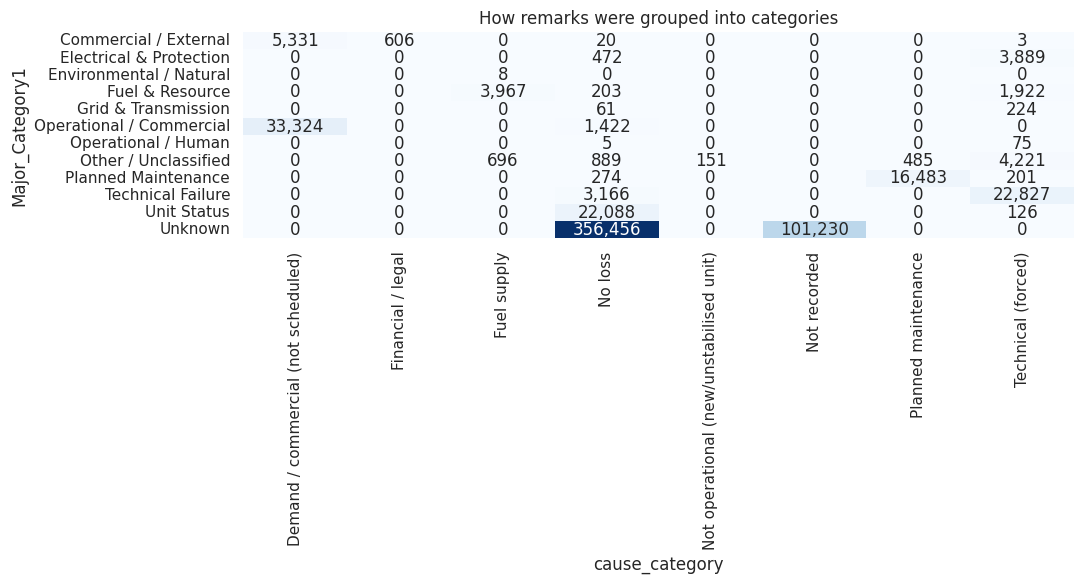

In [12]:
ct = pd.crosstab(clean.Major_Category1, clean.cause_category)
plt.figure(figsize=(11,6))
sns.heatmap(ct, annot=True, fmt=',d', cmap='Blues', cbar=False)
plt.title('How remarks were grouped into categories'); plt.tight_layout(); plt.show()

Note that `Major_Category1 = Unknown` corresponds to rows with no remark. Many of those rows also have no loss, which is expected. `cause_recorded` flags whether a cause exists for rows that lost capacity.

---
# 4. Analysis of the cleaned data
`loss_mw` is the capacity lost on a unit-day. Summing it over days gives **MW-days**, a measure of cumulative lost capacity. It is not energy (MWh), so it is used here for comparison rather than as an absolute energy figure.

In [13]:
clean['month'] = clean.date.dt.month
clean['is_outage'] = clean.outage_type.ne('No Outage')
clean['loss_share'] = clean.loss_mw / clean.monitored_capacity.replace(0, np.nan)
print(clean[['monitored_capacity','loss_mw','outage_age_days']].describe())

       monitored_capacity    loss_mw  outage_age_days
count          574,882.00 580,825.00       100,177.00
mean               274.92      88.53           256.07
std                243.29     181.39           557.92
min                  0.00       0.00             0.00
25%                 75.00       0.00             4.00
50%                210.00       0.00            23.00
75%                464.00     100.00           143.00
max              1,035.00   1,000.00         3,144.00


## 4.1 Data coverage over time

In [14]:
cov = clean.groupby('Year').agg(units=('power_station_unit','size'), days=('date','nunique'))
cov['avg_units_per_day'] = cov.units / cov.days
all_days = pd.date_range(clean.date.min(), clean.date.max())
missing_days = all_days.difference(clean.date.unique())
print(f'{len(missing_days)} calendar days have no data at all (same gap exists in the raw file).')
print(pd.Series(missing_days.year).value_counts().sort_index().to_string())
cov

77 calendar days have no data at all (same gap exists in the raw file).
2019     3
2020    74


,units,days,avg_units_per_day
Year,,,
2018,84690,365,232.03
2019,87324,362,241.23
2020,68836,292,235.74
2021,84037,365,230.24
2022,85162,365,233.32
2023,86387,365,236.68
2024,84389,345,244.61


## 4.2 Outage type mix

                       unit-days  share
outage_type                            
No Outage                 484963  83.50
Long Duration Outage       45002   7.75
Short Duration Outage      27859   4.80
Planned Outage             14670   2.53
Unit Synchronised           8331   1.43


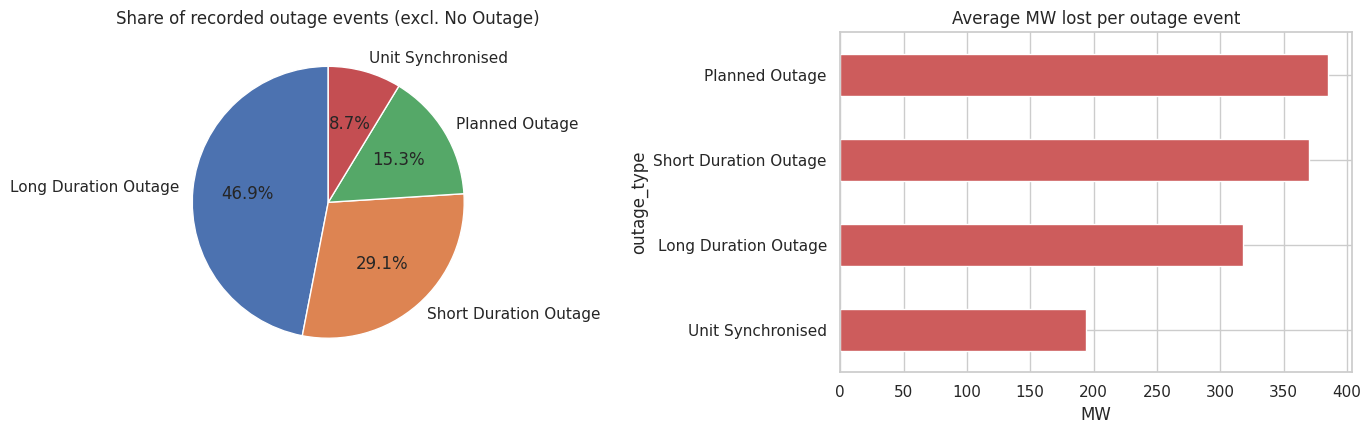

In [15]:
ot = clean.outage_type.value_counts()
print(ot.to_frame('unit-days').assign(share=lambda d: d['unit-days']/d['unit-days'].sum()*100))

fig, axes = plt.subplots(1, 2, figsize=(14,4.5))
outage_only = ot.drop('No Outage')
axes[0].pie(outage_only, labels=outage_only.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Share of recorded outage events (excl. No Outage)')
by_type = clean[clean.is_outage].groupby('outage_type').loss_mw.mean().sort_values()
by_type.plot.barh(ax=axes[1], color='indianred'); axes[1].set_title('Average MW lost per outage event'); axes[1].set_xlabel('MW')
plt.tight_layout(); plt.show()

## 4.3 Yearly trend

In [16]:
yr = clean.groupby('Year').agg(
    unit_days=('loss_mw','size'),
    outage_events=('is_outage','sum'),
    total_loss_mw_days=('loss_mw','sum'),
    avg_loss_per_unit_day=('loss_mw','mean'),
)
yr['outage_event_rate_%'] = yr.outage_events / yr.unit_days * 100
yr

,unit_days,outage_events,total_loss_mw_days,avg_loss_per_unit_day,outage_event_rate_%
Year,,,,,
2018,84690,14401,"6,299,433.30",74.38,17.00
2019,87324,15177,"7,644,743.80",87.54,17.38
2020,68836,17451,"8,081,184.99",117.40,25.35
2021,84037,15823,"8,377,146.90",99.68,18.83
2022,85162,13568,"7,816,243.44",91.78,15.93
2023,86387,10151,"7,016,752.88",81.22,11.75
2024,84389,9291,"6,183,134.90",73.27,11.01


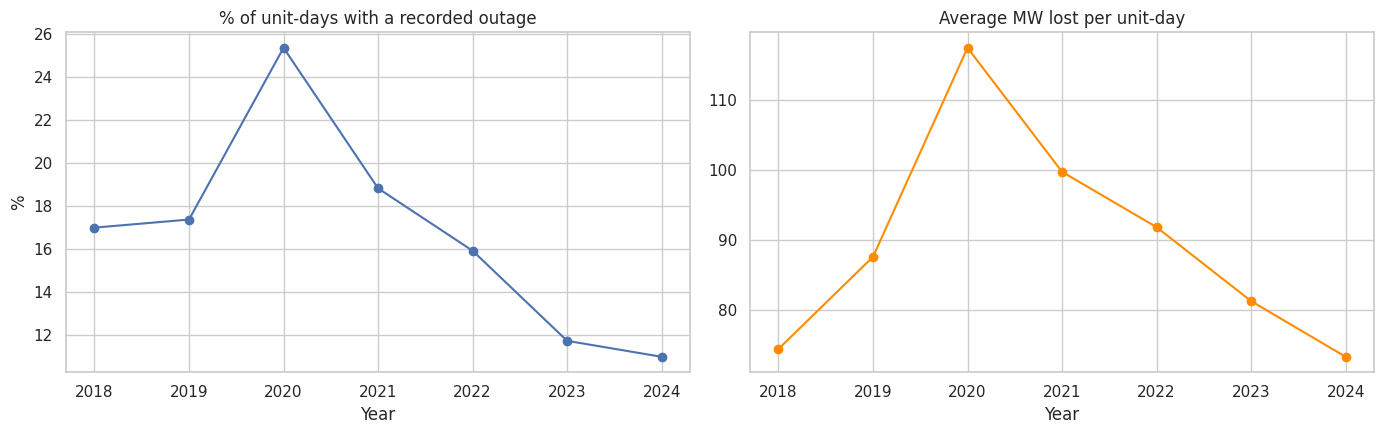

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14,4.5))
yr['outage_event_rate_%'].plot(marker='o', ax=axes[0]); axes[0].set_title('% of unit-days with a recorded outage'); axes[0].set_ylabel('%')
yr['avg_loss_per_unit_day'].plot(marker='o', color='darkorange', ax=axes[1]); axes[1].set_title('Average MW lost per unit-day')
for a in axes: a.set_xticks(yr.index)
plt.tight_layout(); plt.show()

## 4.4 Monthly trend and seasonality

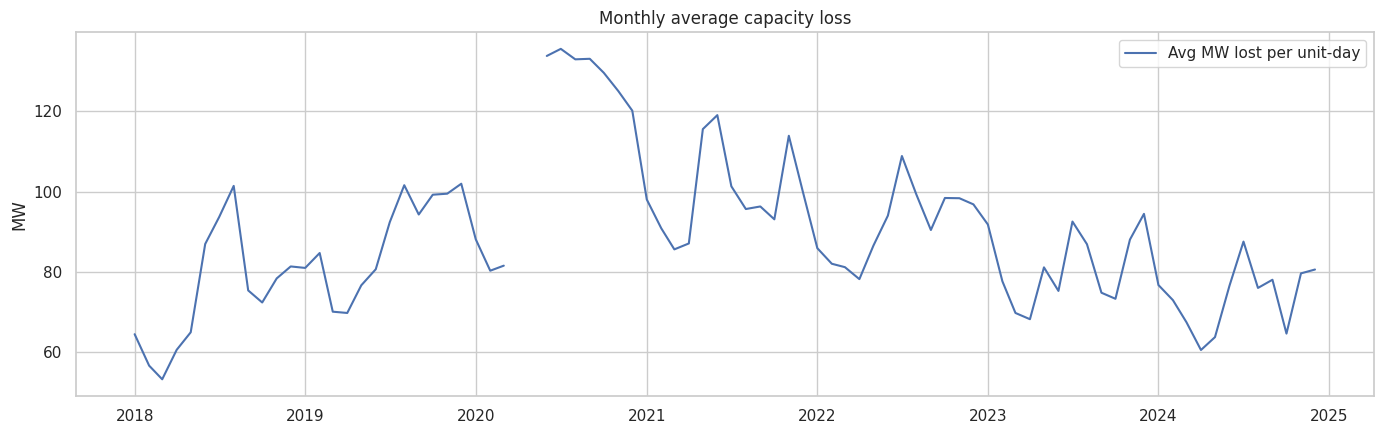

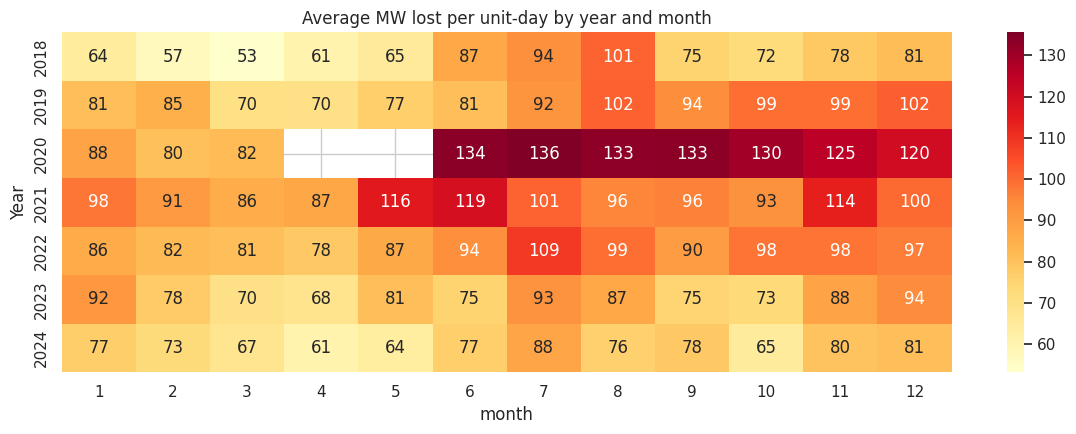

In [18]:
monthly = clean.set_index('date').resample('MS').agg(avg_loss=('loss_mw','mean'), outage_rate=('is_outage','mean'))
fig, ax = plt.subplots(figsize=(14,4.5))
ax.plot(monthly.index, monthly.avg_loss, label='Avg MW lost per unit-day')
ax.set_ylabel('MW'); ax.set_title('Monthly average capacity loss')
ax.legend(); plt.tight_layout(); plt.show()

pivot = clean.pivot_table(index='Year', columns='month', values='loss_mw', aggfunc='mean')
plt.figure(figsize=(12,4.5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Average MW lost per unit-day by year and month'); plt.tight_layout(); plt.show()

## 4.5 State comparison

In [19]:
st = clean.groupby('state_name').agg(
    unit_days=('loss_mw','size'),
    units=('power_station_unit', 'size'),
    stations=('power_station','nunique'),
    avg_capacity=('monitored_capacity','mean'),
    avg_loss=('loss_mw','mean'),
    outage_rate=('is_outage','mean'),
    total_loss=('loss_mw','sum'),
).drop(columns='units')
st['outage_rate'] *= 100
st['share_of_total_loss_%'] = st.total_loss / st.total_loss.sum() * 100
st = st.sort_values('total_loss', ascending=False)
st

,unit_days,stations,avg_capacity,avg_loss,outage_rate,total_loss,share_of_total_loss_%
state_name,,,,,,,
Andhra Pradesh,134717,31,336.00,130.96,20.16,"17,642,972.54",34.31
Tamil Nadu,210082,64,225.54,69.75,17.77,"14,653,698.74",28.50
Karnataka,108911,28,317.40,116.16,21.44,"12,650,609.70",24.60
Telangana,77373,19,335.56,59.33,10.37,"4,590,580.50",8.93
Kerala,46564,20,137.95,40.39,0.00,"1,880,746.23",3.66
Puducherry,2459,1,32.50,0.01,0.00,32.50,0.00
Lakshadweep,719,1,26.83,0.00,0.00,0.00,0.00


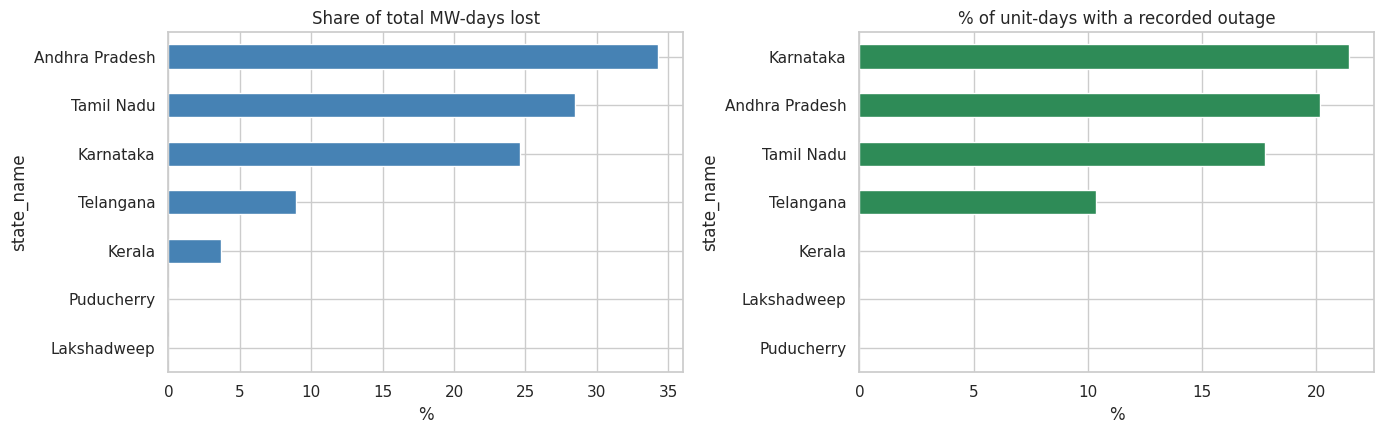

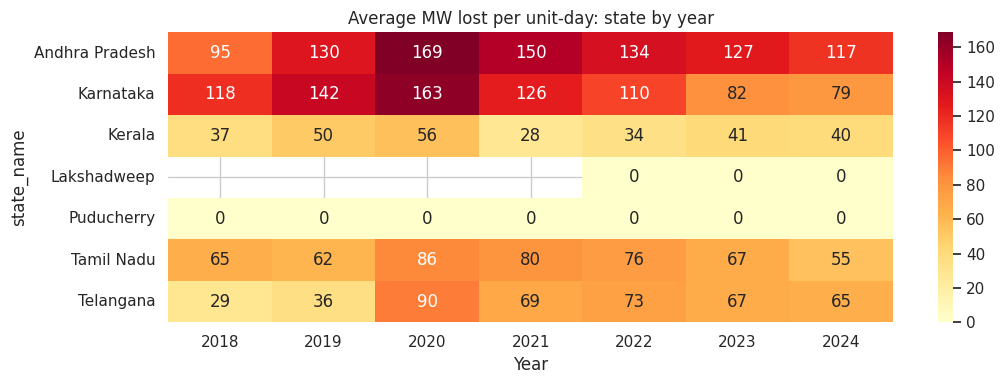

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14,4.5))
st['share_of_total_loss_%'].sort_values().plot.barh(ax=axes[0], color='steelblue'); axes[0].set_title('Share of total MW-days lost'); axes[0].set_xlabel('%')
st['outage_rate'].sort_values().plot.barh(ax=axes[1], color='seagreen'); axes[1].set_title('% of unit-days with a recorded outage'); axes[1].set_xlabel('%')
plt.tight_layout(); plt.show()

sy = clean.pivot_table(index='state_name', columns='Year', values='loss_mw', aggfunc='mean')
plt.figure(figsize=(11,4)); sns.heatmap(sy, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Average MW lost per unit-day: state by year'); plt.tight_layout(); plt.show()

## 4.6 Fuel type and sector

,unit_days,avg_capacity,avg_loss,outage_rate,total_loss,share_of_total_loss_%
fuel_type,,,,,,
Coal/Lignite,313157,336.35,100.01,29.09,"31,317,765.50",60.91
Gas,58926,269.42,205.30,0.00,"12,097,261.36",23.53
Hydro,172063,169.08,34.59,0.00,"5,952,217.35",11.58
Nuclear,19946,415.00,102.76,23.87,"2,049,620.00",3.99
Diesel,16733,73.77,0.11,0.00,"1,776.00",0.00


,unit_days,avg_loss,outage_rate
sector,,,
Central,112428,86.60,22.14
Private,118897,177.33,25.97
State,349500,58.94,11.47


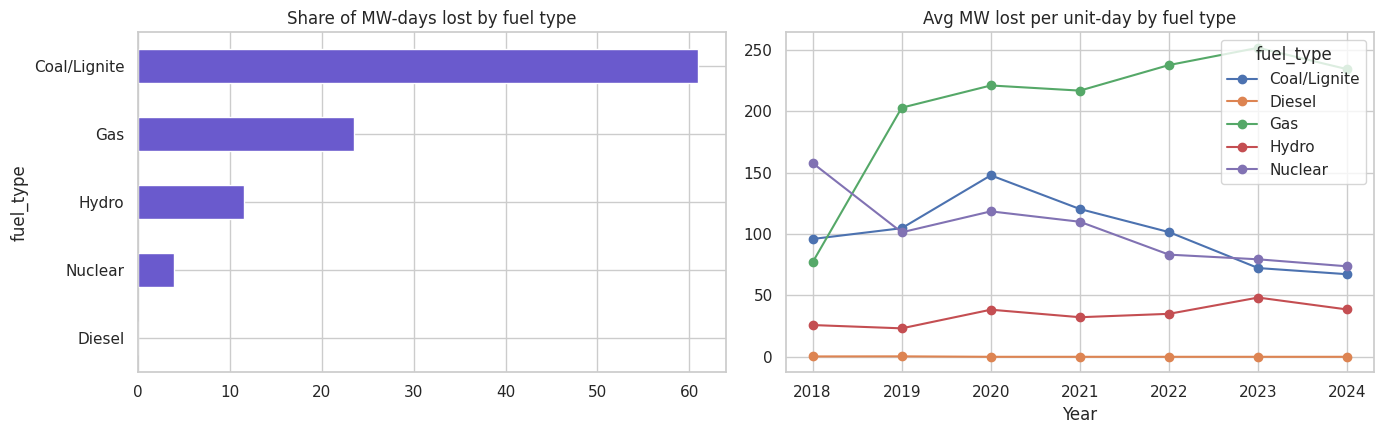

In [21]:
fs = clean.groupby('fuel_type').agg(
    unit_days=('loss_mw','size'), avg_capacity=('monitored_capacity','mean'),
    avg_loss=('loss_mw','mean'), outage_rate=('is_outage','mean'), total_loss=('loss_mw','sum'))
fs['outage_rate'] *= 100
fs['share_of_total_loss_%'] = fs.total_loss / fs.total_loss.sum() * 100
display(fs.sort_values('total_loss', ascending=False))

sec = clean.groupby('sector').agg(unit_days=('loss_mw','size'), avg_loss=('loss_mw','mean'), outage_rate=('is_outage','mean'))
sec['outage_rate'] *= 100
display(sec)

fig, axes = plt.subplots(1, 2, figsize=(14,4.5))
fs['share_of_total_loss_%'].sort_values().plot.barh(ax=axes[0], color='slateblue'); axes[0].set_title('Share of MW-days lost by fuel type')
ft = clean.pivot_table(index='Year', columns='fuel_type', values='loss_mw', aggfunc='mean')
ft.plot(marker='o', ax=axes[1]); axes[1].set_title('Avg MW lost per unit-day by fuel type'); axes[1].set_xticks(ft.index)
plt.tight_layout(); plt.show()

## 4.7 Causes of capacity loss

,unit_days,total_loss,avg_loss,share_%
cause_category,,,,
Not recorded,101230,"18,065,564.71",178.46,35.13
Technical (forced),33488,"12,359,890.00",369.08,24.04
Demand / commercial (not scheduled),38655,"12,016,198.00",310.86,23.37
Planned maintenance,16968,"6,240,185.00",367.76,12.14
Fuel supply,4671,"2,220,820.00",475.45,4.32
Financial / legal,606,"363,600.00",600.00,0.71
Not operational (new/unstabilised unit),151,"120,800.00",800.00,0.23
No loss,89,"31,582.50",354.86,0.06


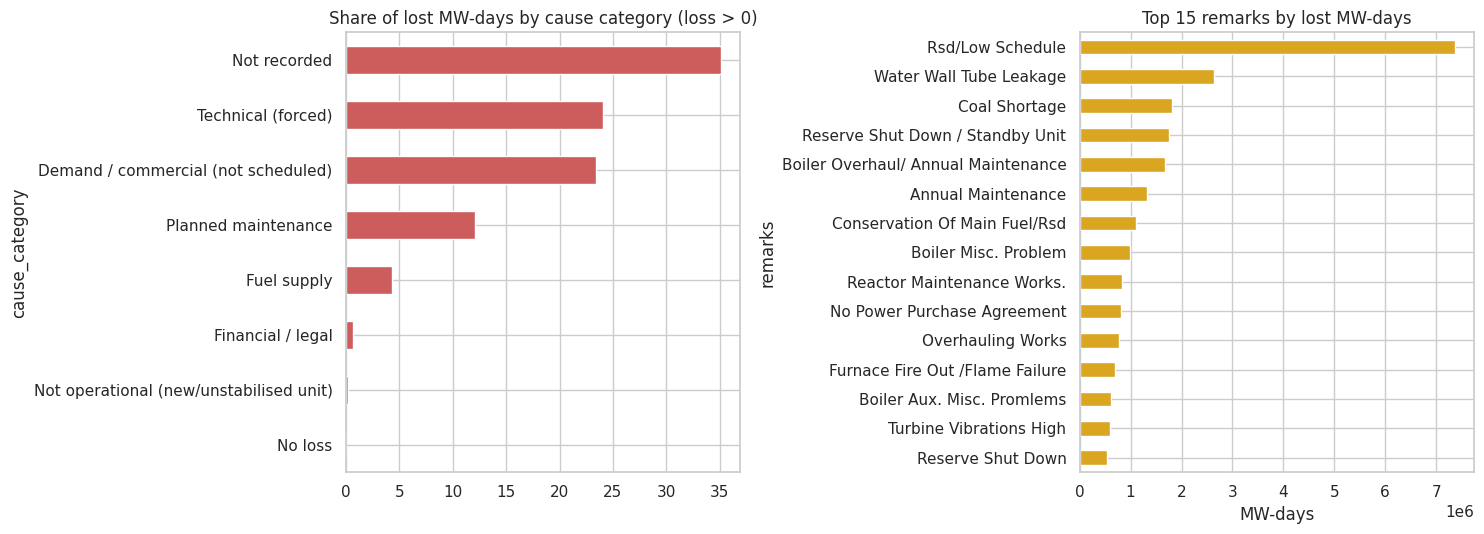

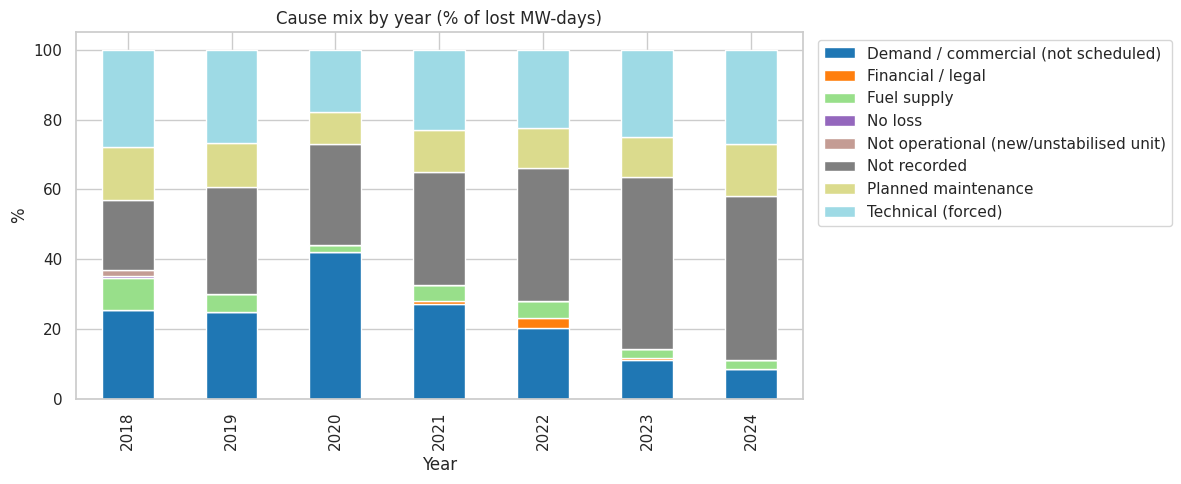

In [22]:
loss_rows = clean[clean.loss_mw > 0]
cause = loss_rows.groupby('cause_category').agg(unit_days=('loss_mw','size'), total_loss=('loss_mw','sum'), avg_loss=('loss_mw','mean'))
cause['share_%'] = cause.total_loss / cause.total_loss.sum() * 100
display(cause.sort_values('total_loss', ascending=False))

top_rem = (loss_rows[loss_rows.remarks != 'No remark'].groupby('remarks').loss_mw.agg(['size','sum'])
           .sort_values('sum', ascending=False).head(15))
fig, axes = plt.subplots(1, 2, figsize=(15,5.5))
cause['share_%'].sort_values().plot.barh(ax=axes[0], color='indianred'); axes[0].set_title('Share of lost MW-days by cause category (loss > 0)')
top_rem['sum'].sort_values().plot.barh(ax=axes[1], color='goldenrod'); axes[1].set_title('Top 15 remarks by lost MW-days'); axes[1].set_xlabel('MW-days')
plt.tight_layout(); plt.show()

cy = loss_rows.pivot_table(index='Year', columns='cause_category', values='loss_mw', aggfunc='sum')
cy.div(cy.sum(axis=1), axis=0).mul(100).plot.bar(stacked=True, figsize=(12,5), colormap='tab20')
plt.title('Cause mix by year (% of lost MW-days)'); plt.ylabel('%'); plt.legend(bbox_to_anchor=(1.01,1), loc='upper left'); plt.tight_layout(); plt.show()

### Data-quality gap: losses with no recorded cause
`cause_recorded` shows how much of the loss can actually be explained.

In [23]:
gap = loss_rows.groupby('Year').agg(rows=('loss_mw','size'), no_cause=('cause_recorded', lambda s: (~s).sum()))
gap['no_cause_%'] = gap.no_cause / gap.rows * 100
gap

,rows,no_cause,no_cause_%
Year,,,
2018,25517,11618,45.53
2019,28502,13876,48.68
2020,29250,12802,43.77
2021,31052,15420,49.66
2022,29429,15499,52.67
2023,27552,17109,62.10
2024,24556,14906,60.70


## 4.8 Worst stations

,state_name,power_station,fuel_type,unit_days,capacity,total_loss,outage_events,outage_rate_%
58,Karnataka,Yermarus Tpp,Coal/Lignite,4918,800.00,"2,372,800.00",2979,60.57
45,Karnataka,Kudgi Stpp,Coal/Lignite,7377,800.00,"2,366,400.00",3022,40.97
34,Karnataka,Bellary Tps,Coal/Lignite,7377,700.00,"1,822,500.00",2912,39.47
48,Karnataka,Raichur Tps,Coal/Lignite,19672,250.00,"1,790,820.00",8245,41.91
115,Tamil Nadu,Muthiara Tpp,Coal/Lignite,4918,600.00,"1,686,000.00",2744,55.80
5,Andhra Pradesh,Grel Ccpp (Rajahmundry),Gas,2459,768.00,"1,588,224.00",0,0.00
30,Andhra Pradesh,Vizag Tpp,Coal/Lignite,4918,520.00,"1,540,760.00",2998,60.96
11,Andhra Pradesh,Kondapalli St-3 Ccpp,Gas,2459,742.00,"1,533,714.00",0,0.00
54,Karnataka,Udupi Tpp,Coal/Lignite,4022,600.00,"1,493,400.00",2528,62.85
21,Andhra Pradesh,Rayalaseema Tps,Coal/Lignite,14754,600.00,"1,347,990.00",5077,34.41


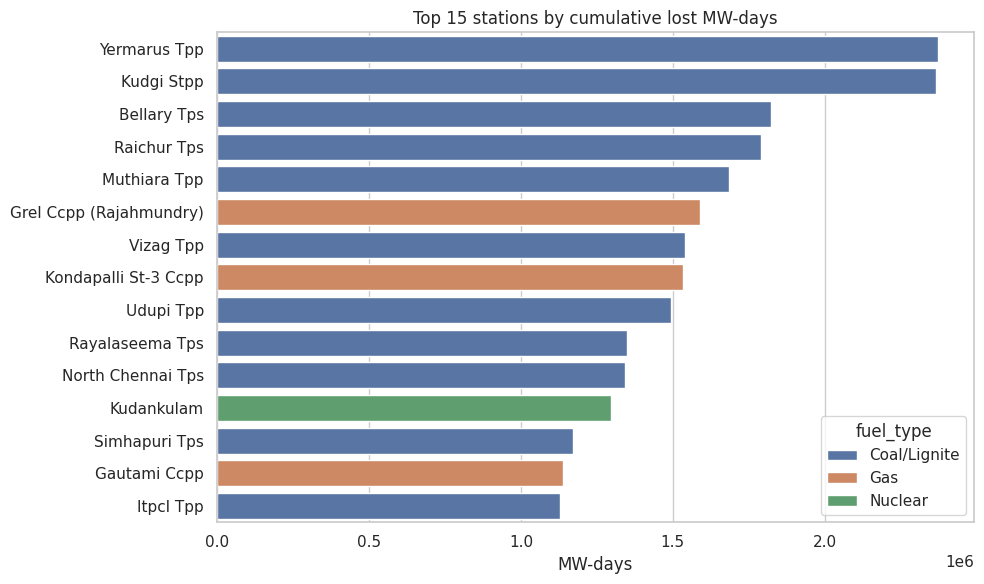

In [24]:
stn = clean.groupby(['state_name','power_station','fuel_type']).agg(
    unit_days=('loss_mw','size'), capacity=('monitored_capacity','max'),
    total_loss=('loss_mw','sum'), outage_events=('is_outage','sum')).reset_index()
stn['outage_rate_%'] = stn.outage_events / stn.unit_days * 100
top = stn.sort_values('total_loss', ascending=False).head(15)
display(top)

plt.figure(figsize=(10,6))
sns.barplot(data=top, y='power_station', x='total_loss', hue='fuel_type', dodge=False)
plt.title('Top 15 stations by cumulative lost MW-days'); plt.xlabel('MW-days'); plt.ylabel(''); plt.tight_layout(); plt.show()

## 4.9 Long-running outages

count   44,724.00
mean       445.25
std        585.06
min          0.00
25%         45.00
50%        147.00
75%        635.00
max      2,477.00
Name: outage_age_days, dtype: float64


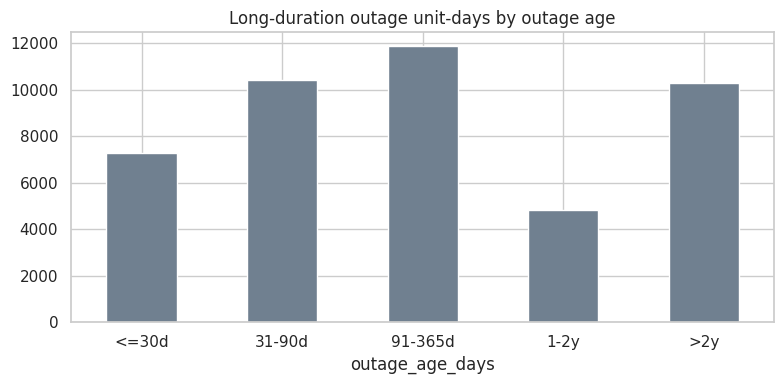

longest_outage_age_days
power_station      power_station_unit                         
Madras A.P.S       Unit 1                             2,477.00
Simhapuri Tps      Unit 1                             2,282.00
Tuticorin (P) Tpp  Unit 1                             2,206.00
                   Unit 2                             2,193.00
Simhapuri Tps      Unit 4                             2,165.00
                   Unit 2                             1,793.00
                   Unit 3                             1,678.00
Thamminapatnam Tps Unit 1                             1,057.00
                   Unit 2                               986.00
Kothagudem Tps     Unit 3                               680.00

In [25]:
active = clean[clean.outage_type.eq('Long Duration Outage') & clean.outage_age_days.notna()]
print(active.outage_age_days.describe())
bins = [-1, 30, 90, 365, 730, 5000]
labels = ['<=30d','31-90d','91-365d','1-2y','>2y']
age = pd.cut(active.outage_age_days, bins=bins, labels=labels).value_counts().reindex(labels)
age.plot.bar(color='slategray', figsize=(8,4)); plt.title('Long-duration outage unit-days by outage age'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

stuck = (active.groupby(['power_station','power_station_unit']).outage_age_days.max()
         .sort_values(ascending=False).head(10))
display(stuck.to_frame('longest_outage_age_days'))

## 4.10 Outage size relative to unit capacity

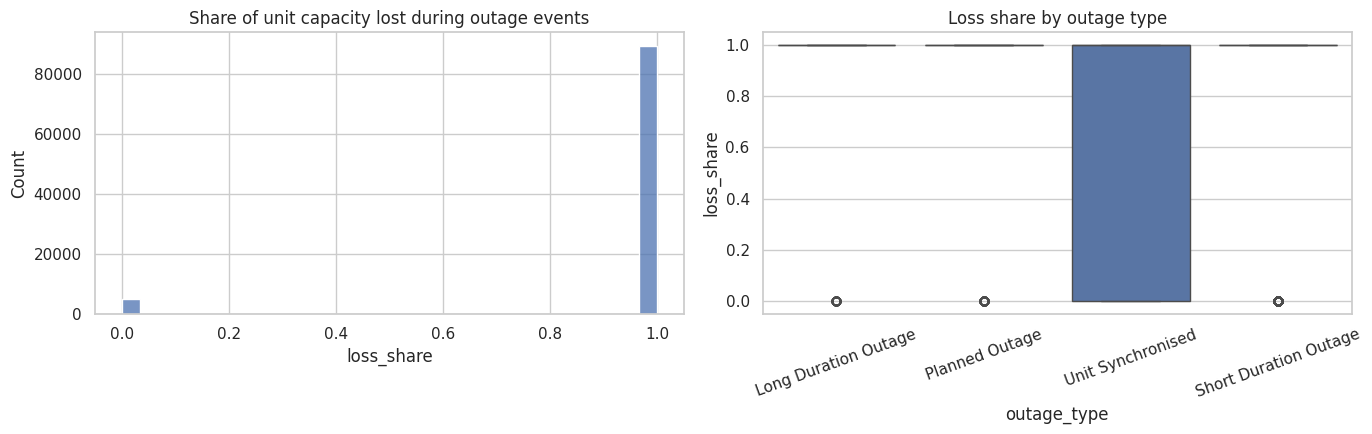

Outage events losing the full unit capacity: 94.6%


In [26]:
o = clean[clean.is_outage & clean.loss_share.notna()]
fig, axes = plt.subplots(1, 2, figsize=(14,4.5))
sns.histplot(o.loss_share.clip(0,1), bins=30, ax=axes[0]); axes[0].set_title('Share of unit capacity lost during outage events')
sns.boxplot(data=o, x='outage_type', y='loss_share', ax=axes[1]); axes[1].set_title('Loss share by outage type'); axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
print('Outage events losing the full unit capacity: {:.1%}'.format((o.loss_share >= 0.999).mean()))

## 5. Data quality checks on the cleaned file

In [27]:
checks = {
    'Duplicate unit-day keys': int(clean.duplicated(key).sum()),
    'Rows where loss_mw > monitored_capacity': int((clean.loss_mw > clean.monitored_capacity).sum()),
    'Negative loss_mw': int((clean.loss_mw < 0).sum()),
    'Rows with missing monitored_capacity': int(clean.monitored_capacity.isna().sum()),
    'Rows with monitored_capacity == 0': int((clean.monitored_capacity == 0).sum()),
    'Calendar days with no data': int(len(missing_days)),
    'Outage rows with no cause recorded': int((~loss_rows.cause_recorded).sum()),
}
pd.Series(checks, name='count').to_frame()

,count
Duplicate unit-day keys,0
Rows where loss_mw > monitored_capacity,0
Negative loss_mw,0
Rows with missing monitored_capacity,5943
Rows with monitored_capacity == 0,28231
Calendar days with no data,77
Outage rows with no cause recorded,101230


In [28]:
# Which stations have missing capacity?
clean[clean.monitored_capacity.isna()].groupby(['state_name','power_station']).size().sort_values(ascending=False).head(10)

state_name      power_station      
Telangana       Yadadri Tps            2340
Tamil Nadu      Ennore Sctpp           1031
Kerala          Pallivasal New Hps      993
Telangana       Telangana Stpp          604
Andhra Pradesh  Polavaram Hps           277
                Pinnapuram Hps          274
Tamil Nadu      Bhavini Pfbr            274
Telangana       Telangana Stpp Ph-1     150
dtype: int64

## 6. Key findings

In [29]:
total_loss = clean.loss_mw.sum()
top_state = st.index[0]; top_fuel = fs.sort_values('total_loss', ascending=False).index[0]
top_cause = cause.sort_values('total_loss', ascending=False).index[0]
worst_year = yr['avg_loss_per_unit_day'].idxmax(); best_year = yr['avg_loss_per_unit_day'].idxmin()

print(f'''
CLEANING IMPACT
- {len(raw):,} raw rows -> {len(clean):,} cleaned rows ({len(clean)/len(raw):.1%} retained).
- Reduction = Southern-region filter + date window + removal of {len(s2)-len(s3):,} duplicate unit-day records.
- Blank outage_type, remarks and cap_under_outage values were standardised so every row is usable in Power BI.
- 8 columns added (Year, cause categories, status flags, outage age); station_type and cap_under_outage were renamed to fuel_type and loss_mw.

ANALYSIS
- Total lost capacity: {total_loss:,.0f} MW-days across {clean.date.nunique():,} days of data.
- {top_state} has the largest share of losses ({st.loc[top_state,"share_of_total_loss_%"]:.1f}%).
- {top_fuel} units account for {fs.loc[top_fuel,"share_of_total_loss_%"]:.1f}% of lost MW-days.
- Leading cause category (where loss > 0): {top_cause} ({cause.loc[top_cause,"share_%"]:.1f}%).
- Average loss per unit-day was highest in {worst_year} ({yr.loc[worst_year,"avg_loss_per_unit_day"]:.1f} MW) and lowest in {best_year} ({yr.loc[best_year,"avg_loss_per_unit_day"]:.1f} MW).
''')


CLEANING IMPACT
- 4,265,703 raw rows -> 580,825 cleaned rows (13.6% retained).
- Reduction = Southern-region filter + date window + removal of 377,003 duplicate unit-day records.
- Blank outage_type, remarks and cap_under_outage values were standardised so every row is usable in Power BI.
- 8 columns added (Year, cause categories, status flags, outage age); station_type and cap_under_outage were renamed to fuel_type and loss_mw.

ANALYSIS
- Total lost capacity: 51,418,640 MW-days across 2,459 days of data.
- Andhra Pradesh has the largest share of losses (34.3%).
- Coal/Lignite units account for 60.9% of lost MW-days.
- Leading cause category (where loss > 0): Not recorded (35.1%).
- Average loss per unit-day was highest in 2020 (117.4 MW) and lowest in 2024 (73.3 MW).



### Caveats
- `loss_mw` is capacity (MW), so totals are MW-days and not MWh.
- 77 calendar days are absent from both files, so trends use the days available.
- In 89 rows `loss_mw` was imputed as full capacity where the raw loss was blank (short-duration outages); this is a small effect.
- Rows with `shortfall_not_outage = True` have a loss but no formal outage, i.e. backing down or low schedule, and are counted in loss totals but not in outage-event counts.